# **Phase 3 - Vehicle Classification**

This is an open ended phase. You must build a classifier for the Stanford Cars Dataset. You can use any techniques and knowledge from Phase 1 & 2 to aid you. The ultimate goal is to get as good performance as you can on the test set.

Please follow TA instructions in lab to learn how to access the data.

# **Imports**

Import all the libraries you need for your project. Google Drive mounting code is provided if you plan to use Colab.

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import os, copy, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import loadmat

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") #uses gpu, if no gpu use cpu instead

root = "/workspace/data"
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] #per-channel average and spread of ImageNet dataset, the pretrained ResNet was trained on images that were normalized using these numbers

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)), #resizes each to 224x224, network requires a fixed size
    transforms.ToTensor(), #converts PIL image to PyTorch tensor and rescales pixel values
    transforms.Normalize(mean, std),
])

# **1. Load Dataset**
The Stanford Dataset is provided in ```torchvision.datasets```. However, you must code your own Dataset class to load the dataset.

You will need to create your inherit from ```Dataset``` class to load the dataset and overload the ```___init__()```, ```__len__()```, and ```__getitem__()``` functions.

You will find the [following link](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) useful to help create the dataset class.

Please also create another function or method in the class: ```show_imgs()``` to help visualize the data. Similar to Phase 1 and 2, you need to display random images and label. Please display 3-5 unique classes.

In [3]:
class CarDataSet(Dataset):

    def __init__(self, img_dir, annos_path, meta_path=None, transform=None):
        self.img_dir, self.transform = img_dir, transform #saves folder and transform on object
        self.class_names = None
        
        if annos_path.endswith(".mat"): #make sure annotation file is in .mat
            annos = loadmat(annos_path, squeeze_me=True)['annotations'] #reads MATLAB file and pulls out annotations table, one record per image
            self.samples = [(str(a['fname']), int(a['class']) - 1) for a in annos] #builds the main list
        else:  
            df = pd.read_csv(annos_path) #loads CSV into table
            
            if str(df.columns[0]).lower().endswith((".jpg", ".jpeg", ".png")):   # no header row
                df = pd.read_csv(annos_path, header=None)
            cols = {str(c).lower(): c for c in df.columns} #make a lookup form lowercase column names to real names
            fcol = next((cols[k] for k in ("fname", "filename", "file", "image", "img", "path") if k in cols), df.columns[0]) #finds filename column by common names, if no match goes back to first column.
            lcol = next((cols[k] for k in ("class", "label", "target", "make", "y") if k in cols), df.columns[-1]) #does the same for label columns
            
            labels = df[lcol].astype(int) #converts labels to integers, if smallest label is 1, is 1-indexed, so makes it 0-indexed
            if labels.min() == 1:
                labels = labels - 1
            self.samples = list(zip(df[fcol].astype(str), labels)) #pairs filenames with labels        
        if meta_path is not None and meta_path.endswith(".mat"):
            self.class_names = [str(c) for c in loadmat(meta_path, squeeze_me=True)['class_names']]

    def __len__(self):
        return len(self.samples) #returns number of samples

    def __getitem__(self, idx): #called with index to get one item.
        fname, label = self.samples[idx]
        img = Image.open(os.path.join(self.img_dir, fname)).convert("RGB") #opens image wit PIL and forces it into 3 color channels
        
        if self.transform: #if transform was given, applies it and returns it
            img = self.transform(img)
        return img, label

In [4]:
# Load the Data
train_data = CarDataSet(f"{root}/cars_train", f"{root}/devkit/cars_train_annos.mat", f"{root}/cars_annos.mat", transform=eval_tf) #builds training dataset with the 4 arguments
test_data = CarDataSet(f"{root}/cars_test", f"{root}/cars_test_annos_withlabels.mat", f"{root}/cars_annos.mat", transform=eval_tf)

# Batch Size
batch_size = 64

# Import to Dataloaders
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=False, num_workers=0) #wraps dataset so it can be looped in batches of 64, splits the 8144 images into 128 batches

test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0) #same for test set, except now it gives 126 batches

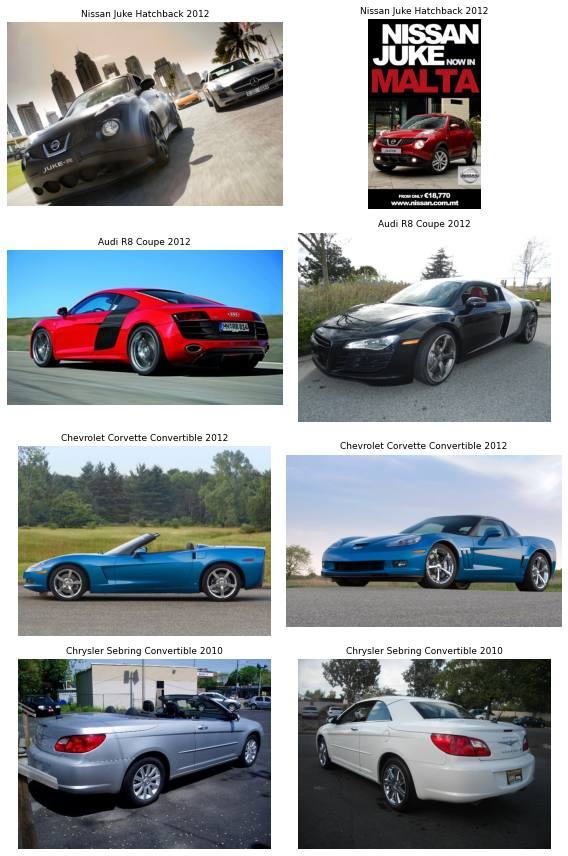

In [5]:
def show_imgs(dataset, n_classes=4, imgs_per_class=2):
    by_class = {}
    for fname, label in dataset.samples: #loop over each filename and label pair
        by_class.setdefault(label, []).append(fname)
    chosen = random.sample(list(by_class.keys()), n_classes) #takes list of all class labels and randomly picks n_classes of them, making it unique classes
    fig, axes = plt.subplots(n_classes, imgs_per_class, figsize=(4 * imgs_per_class, 3 * n_classes)) #creates figure with 1 row per class and 1 column per image
    axes = np.atleast_2d(axes)
    for r, label in enumerate(chosen): #draws the images, looping over chosen classes
        for c, fname in enumerate(random.sample(by_class[label], imgs_per_class)):
            img = Image.open(os.path.join(dataset.img_dir, fname)).convert("RGB") #opens image
            axes[r, c].imshow(img) #draws the photo in panel at row r, column c
            axes[r, c].set_title(dataset.class_names[label], fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout()
    plt.show()

show_imgs(train_data)

# **2. Define your Model Architecture**

It is up to you to decide which model you use. You can create your own CNN or use transfer learning.

In [6]:
# Model definition
model = models.resnet18(pretrained=True) #builds ResNet-18 and loads ImageNet weights
model = model.to(device).eval()

stem = nn.Sequential(model.conv1, model.bn1, model.relu, model.maxpool, model.layer1, model.layer2, model.layer3).eval() # chains the first part of ResNet-18, stopping before layer4. Ensures only early layers are frozen 

# Load Model onto GPU
def extract(loader, flip=False):
    feats, flips, labels = [], [], []
    with torch.no_grad(): #turn off gradient tracking, only reading features, so it saves time
        for i, (x, y) in enumerate(loader):
            x = x.to(device)
            feats.append(stem(x).half().cpu()) #runs batch through frozen steam, then .half converts numbers to 16-bit
            if flip:
                flips.append(stem(torch.flip(x, dims=[3])).half().cpu()) #mirrors image left-to-right
            labels.append(y) #saves labels
            if i % 20 == 0: #prints progress every 20 batches 
                print(f"batch {i}/{len(loader)}")
    f = torch.cat(feats) #joins per-batch reslts into one tensor
    if flip: #stacks original and flipped features into a single tensior with new first dimension of size 2.
        f = torch.stack([f, torch.cat(flips)])
    return f, torch.cat(labels)

train_feats, train_labels = extract(train_loader, flip=True)
test_feats, test_labels = extract(test_loader)
torch.save((train_feats, train_labels, test_feats, test_labels), "/workspace/data/feats.pt")

batch 0/128
batch 20/128
batch 40/128
batch 60/128
batch 80/128
batch 100/128
batch 120/128
batch 0/126
batch 20/126
batch 40/126
batch 60/126
batch 80/126
batch 100/126
batch 120/126


# **3. Define Optimizer, Scheduler, Loss, etc.**

You chose the loss function and optimizer.

In [7]:
# Loss Function
def loss_fn(logits, y, eps=0.1): 
    logp = F.log_softmax(logits, 1) #turns raw scores into log-probabilities over 196 classes
    return (1 - eps) * F.nll_loss(logp, y) + eps * (-logp.mean(1)).mean() #cross-entropy with label smoothing

# Optimizer
class Head(nn.Module):
    def __init__(self):
        super().__init__() #parent class setup
        self.layer4 = copy.deepcopy(model.layer4) #makes independent copy of pretrained layer4, deepcopy used so training updates these weights, not on original
        self.fc = nn.Linear(512, 196) #512 dimensional output to 196 new classes

    def _run(self, x):
        f = self.layer4(x.float().to(device)).mean((2, 3)) #processes one batch, converters fp16 maps back to 320-bit and moves them to compute device
        f = F.dropout(f, 0.3, self.training) #randomly zeroes 30% of features during training to reduce overfitting
        return self.fc(f)

    def forward(self, x):
        if self.training:#in training mode, processes batch directly, in eval mode, the input is whole test set, so process in chunks of 256 to not run out of memory
            return self._run(x)
        return torch.cat([self._run(x[i:i+256]).cpu() for i in range(0, len(x), 256)])

clf = Head().to(device)
epochs = 12
optimizer = torch.optim.AdamW([{"params": clf.layer4.parameters(), "lr": 3e-4}, #uses the two different learning rates
                               {"params": clf.fc.parameters(),     "lr": 1e-3}],
                              weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

# **4. Train your Network**

Feel free to use your `train()` from either Phase 1 or Phase 2, whichever you feel is a better choice to understand training to tune it better. Please make sure to plot your learning curves, for both loss and accuracy! Again, this can be per iterations or epoch depending on what you see fit. You will need to save your model as `.pth` file! [This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [8]:
# Train Network
def evaluate_feats(feats, labels):
    clf.eval() #switch to eval mode, and runs all cached feature maps with gradient tracking off
    with torch.no_grad():
        out = clf(feats).cpu()
    return F.cross_entropy(out, labels).item(), (out.argmax(1) == labels).float().mean().item() #returns plain cross-entropy loss and accuracy

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
N, bs = train_feats.shape[1], 64

for epoch in range(epochs):
    t0 = time.time() #epoch loop, counts seconds and switches to train mode
    clf.train()
    perm = torch.randperm(N) #random shuffle of indices 0 to N-1
    run_loss, run_correct, seen = 0.0, 0, 0 #running totals
    for b in range(0, N - bs + 1, bs): #steps through shuffled indices 64 at a time
        idx = perm[b:b+bs]
        flip = torch.randint(0, 2, (len(idx),)) #for each image, randomly picks 0 or 1, pulls original features with 0 and mirrored featres with 1
        x = train_feats[flip, idx].float()
        if torch.rand(1).item() < 0.5: #with 50% prob, whole batch is cropped to 12x12 or 14x14, starting at random offset
            i, j = np.random.randint(0, 3, 2)
            x = x[:, :, i:i+12, j:j+12]
        x, y = x.to(device), train_labels[idx].to(device) #moves batch and its matching labels to device
        optimizer.zero_grad() #clears gradients left
        out = clf(x) #forward pass to get logits then loss
        loss = loss_fn(out, y)
        loss.backward() #computes gradients of loss with respect to each trainable weight in layer4 
        optimizer.step()
        run_loss += loss.item() * len(y) #accumulates loss, the # of correct predictions + image count
        run_correct += (out.argmax(1) == y).sum().item()
        seen += len(y)
    scheduler.step() #end epoch

    vl, va = evaluate_feats(test_feats, test_labels) #evaluates on test set afect each epoch
    for k, v in zip(history, (run_loss / seen, run_correct / seen, vl, va)): #pairs history key with epoch's value and appends it
        history[k].append(v)
    print(f"epoch {epoch+1:2d} | train loss {run_loss/seen:.3f} acc {run_correct/seen:.3f} | "
          f"test loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    
model.layer4 = clf.layer4 #puts trained layer4 and new classifier back into original ResNet-18 object, and saves all weights to a .pth file.
model.fc = clf.fc
torch.save(model.state_dict(), "/workspace/stanford_cars_resnet18.pth")

epoch  1 | train loss 4.377 acc 0.138 | test loss 2.856 acc 0.375 | 29s
epoch  2 | train loss 2.615 acc 0.537 | test loss 2.002 acc 0.572 | 31s
epoch  3 | train loss 1.892 acc 0.752 | test loss 1.622 acc 0.643 | 30s
epoch  4 | train loss 1.523 acc 0.881 | test loss 1.490 acc 0.687 | 31s
epoch  5 | train loss 1.319 acc 0.937 | test loss 1.405 acc 0.701 | 31s
epoch  6 | train loss 1.219 acc 0.967 | test loss 1.453 acc 0.720 | 30s
epoch  7 | train loss 1.153 acc 0.982 | test loss 1.408 acc 0.731 | 30s
epoch  8 | train loss 1.117 acc 0.986 | test loss 1.381 acc 0.746 | 31s
epoch  9 | train loss 1.079 acc 0.992 | test loss 1.389 acc 0.753 | 31s
epoch 10 | train loss 1.067 acc 0.995 | test loss 1.412 acc 0.758 | 31s
epoch 11 | train loss 1.055 acc 0.995 | test loss 1.389 acc 0.760 | 30s
epoch 12 | train loss 1.044 acc 0.997 | test loss 1.455 acc 0.758 | 32s


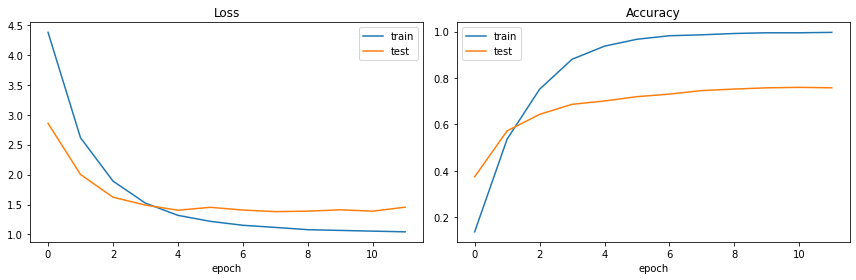

In [9]:
# Plot learning curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4)) #creates a figure 12 inches wide and 4 tall
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["test_loss"], label="test")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["test_acc"], label="test")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# **5. Evaluate**

Now we will evaluate on validation set. The TA's will run your model on the hold-out test set for your final grade.

## **5.1 Average and Per-class Accuracy**

Feel free to use `test_accuracy()` here to get accuracy. You also must show per-class accuracy. You can write your own accuracy function to get per class accuracy or use `classification_report` from `sklearn`.

In [10]:
from sklearn.metrics import classification_report, confusion_matrix

clf.eval()
with torch.no_grad(): #runs all 8041 cached test feaure maps through layer4 and classifier
    logits = clf(test_feats).cpu()
probs = torch.softmax(logits, dim=1) #converts raw scores into probabilities that sum to 1 across the 196 classes
preds = probs.argmax(1) #take class with highest probability
y_true, y_pred = test_labels.numpy(), preds.numpy() #converts true labels and prediction to NumPy arrays

print(f"Overall test accuracy: {(y_true == y_pred).mean():.4f}\n")

per_class = np.array([(y_pred[y_true == c] == c).mean() if (y_true == c).any() else np.nan
                      for c in range(196)]) #loops over all 196 classes, for each class selects predictions for images
order = np.argsort(per_class) #returns class indices sorted from lowest to highest accuracy
print("Worst 10 classes:")
for c in order[:10]:
    print(f"  {per_class[c]:.2f}  {train_data.class_names[c]}") #first 10 entries are worst classes
print("Best 10 classes:")
for c in order[::-1][:10]:
    print(f"  {per_class[c]:.2f}  {train_data.class_names[c]}") #first 10 entries are the best classes

print(classification_report(y_true, y_pred, labels=list(range(196)),
                            target_names=train_data.class_names, zero_division=0))

Overall test accuracy: 0.7580

Worst 10 classes:
  0.28  Chevrolet Express Cargo Van 2007
  0.33  Audi S5 Coupe 2012
  0.38  Audi S4 Sedan 2012
  0.43  Chevrolet Express Van 2007
  0.43  Audi TTS Coupe 2012
  0.47  Chevrolet Impala Sedan 2007
  0.47  Suzuki SX4 Sedan 2012
  0.48  BMW 6 Series Convertible 2007
  0.51  Audi S4 Sedan 2007
  0.51  Mercedes-Benz E-Class Sedan 2012
Best 10 classes:
  1.00  FIAT 500 Abarth 2012
  0.98  AM General Hummer SUV 2000
  0.98  Jeep Wrangler SUV 2012
  0.97  Isuzu Ascender SUV 2008
  0.97  Infiniti QX56 SUV 2011
  0.95  Dodge Caravan Minivan 1997
  0.95  Cadillac CTS-V Sedan 2012
  0.95  Land Rover Range Rover SUV 2012
  0.95  Ford F-450 Super Duty Crew Cab 2012
  0.95  Toyota 4Runner SUV 2012
                                                        precision    recall  f1-score   support

                            AM General Hummer SUV 2000       0.88      0.98      0.92        44
                                   Acura RL Sedan 2012       0.48   

## **5.2 Confusion Matrix**

Please plot the confusion matrix with all classess. Please make this visually readable.

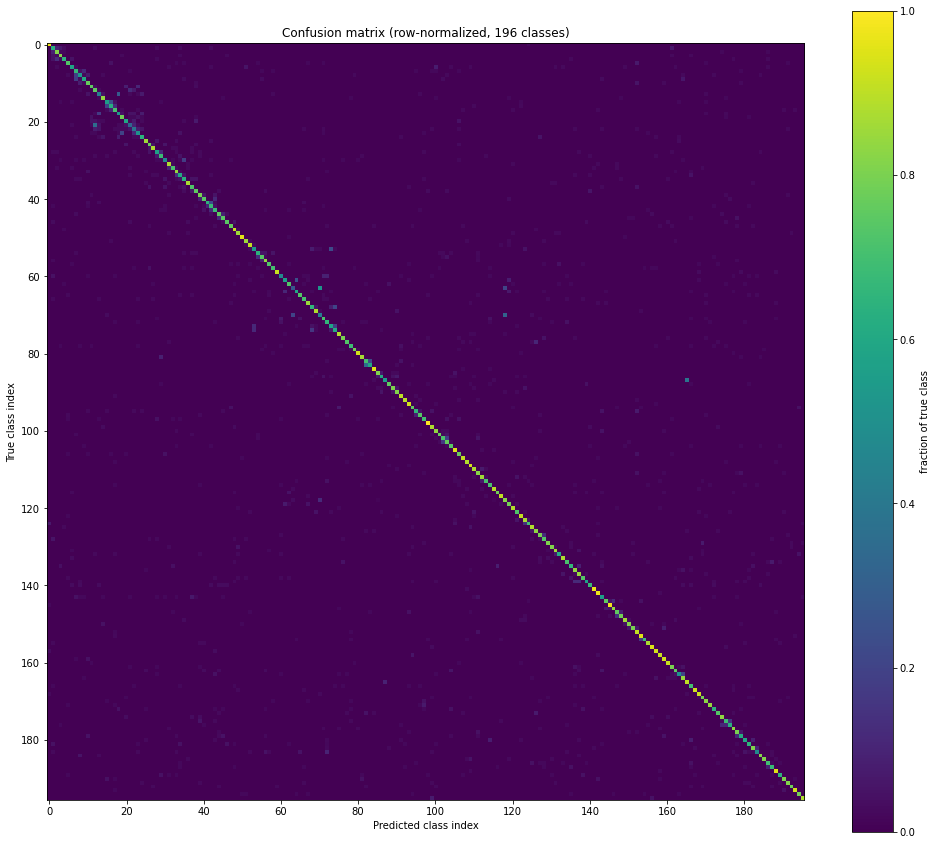

In [11]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(196)), normalize="true") #creates 196x196 table, rows are true lasses and columns are predicted classes

plt.figure(figsize=(14, 12))
plt.imshow(cm, cmap="viridis", vmin=0, vmax=1) #displays matrix as image, one colored square per cell
plt.colorbar(label="fraction of true class")
plt.xlabel("Predicted class index"); plt.ylabel("True class index")
plt.title("Confusion matrix (row-normalized, 196 classes)")
plt.xticks(range(0, 196, 20)); plt.yticks(range(0, 196, 20)) #shows tick only every 20 classes
plt.tight_layout(); plt.show()

## **5.3 Check Model Inference**

Please write a function, `show_predictions()` which will show:


1.   The top 5 confidenct predicted images with an example each.
2.   The bottom 5 confident predicted images, with an example each.

For each image, show the true label, what your model predicted and with what confidence.



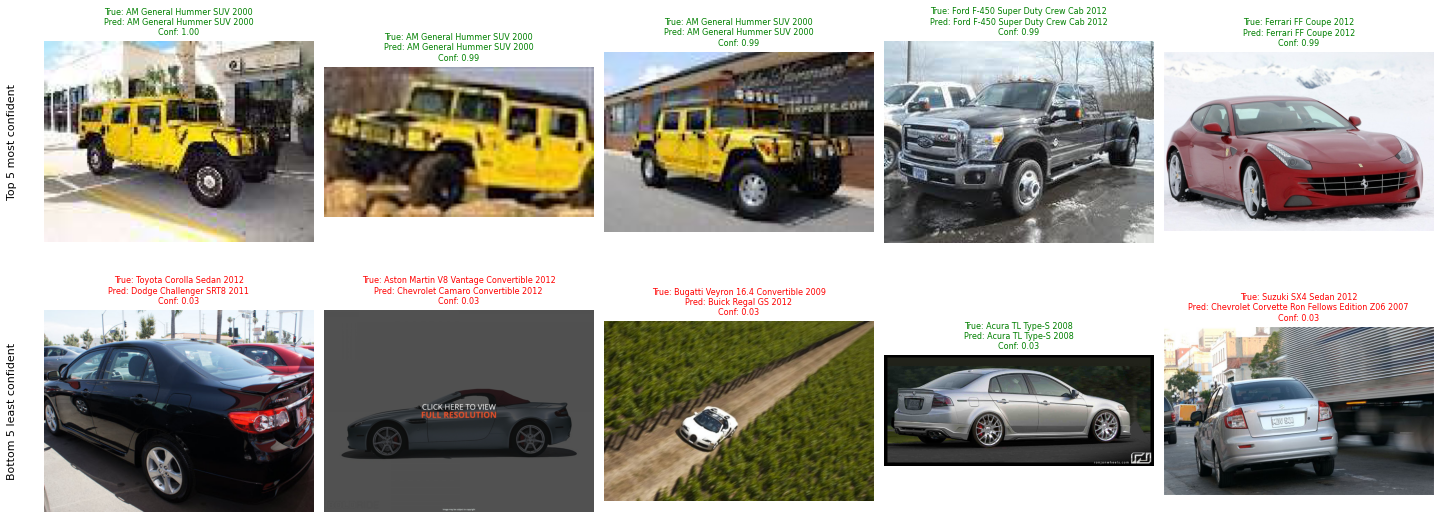

In [12]:
def show_predictions(dataset, probs, labels, k=5):
    conf, pred = probs.max(1) #for each image take highest probability
    order = torch.argsort(conf, descending=True) #return sorting from most to least confident
    groups = [("Top 5 most confident", order[:k]), ("Bottom 5 least confident", order[-k:])] #builds 2 groups the first k indices and the last k indices

    fig, axes = plt.subplots(2, k, figsize=(4 * k, 8)) # 2 row by 5 column grid creation
    for row, (title, idxs) in enumerate(groups):
        for col, i in enumerate(idxs.tolist()):
            fname, _ = dataset.samples[i]
            img = Image.open(os.path.join(dataset.img_dir, fname)).convert("RGB") #looks up filename and opens original photo
            ok = pred[i].item() == labels[i].item() #true if prediction matches label
            axes[row, col].imshow(img)
            axes[row, col].set_title(
                f"True: {dataset.class_names[labels[i].item()]}\n" #shows photo with true class name, predicted class name, and confidence to 2 decimals
                f"Pred: {dataset.class_names[pred[i].item()]}\n"
                f"Conf: {conf[i].item():.2f}",
                fontsize=8, color="green" if ok else "red")
            axes[row, col].axis("off")
        axes[row, 0].text(-0.1, 0.5, title, transform=axes[row, 0].transAxes, #write row label Top 5 most confident or Bottom 5 least confident on left side
                          rotation=90, va="center", ha="right", fontsize=11)
    plt.tight_layout(); plt.show()

show_predictions(test_data, probs, test_labels)

## **6. Report**

Please write a report discussing all your choices and procedure to implement your vehicle classifier. In your report, include all your choices (i.e. hyperparameters, lr, models, loss, optimizer) and explain why you made those choices to achieve your performance. Your report must be thorough and comprehensive, please discuss fully how you were able to obtain a high performance. Please also include an analysis of your model, whether it may be overfitting or underfitting or fitting well and what you may have done to further improve your performance.

Lab Overview
I built a 196-class classififer for Stanford Cars, a dataset that has 8,144 training and 8,041 test images, using transfer learning. The model is a pretrained ResNet-18, which I froze conv1 to layer3, fine tuned layer 4, and added a new 196-way linear head. The final test accuracy is 75.8%, and I reached it in two stages. My first attempt which used a fully frozen backbone with a trained linear head got 39.1% test accuracy, and understanding why it failed led me to my final model.

A couple constraints include limited shared memeory, and not being allowed to download pretrained weights. The only weights that were available were the ResNet-18 weights from Phase 2, so I stayed using those weights. There was also a limited shared memory, in phase 2, I could set num_workers=0. To make fine-tuning work on the CPU, I ran the frozen portions of the network once and cached the 256x14x14 feature maps in fp16. Training only passes cached maps through layer4 and the head, which only took ~30 secs per epoch.

Data+Preprocessing
I wrote a custom Dataset class that reads the .mat annotations, converts the 1-indexed labels to 0-195, and loads images with PIL. Every image is resized to 224x224 and normalized with the ImageNet mean and std, becuase the pretrained weights expects inputs in that distribution. For augmenations, I used a horizontal flip, cached a flpped copy of each training image and for each step of each sample it randomly uses the original or flipped features. I also used a random crop on the feaure map, with a 50% probability a batch is cropped to random 12x12 window of the 14x14 map.

Training choices + model
I used ResNet-18, ImageNet-pretrained, because the only pretrained weights were available offline and were fastest ResNet on CPU. I only trained layer4 and a new linear layer mapping 512 features and 197 classes, adn kept everything else frozen. The early layers learn generic edges and textures that transfer well to any image task, whereas layer4 hold the more task-specfic features, meaning it should be the layer to adapt.

For loss i used cross-entropy with a  label smoothing of 0.1. Cross-entropy is standard for multi-class classification, and smoothing reduced over-confidence when there about ~41 images per class. I used AdamW as the optimizer with a  weight decay of 0.05, because adaptive steps converge quickly and the decoupled weight decay regularizes layer4. I gave layer4 a learning rate of 3e-4 and the head a learning rate of 1e-3. The pretrained layer gets a lower rate so fine tuning doesn't harm the features, while the randomly initialized head needs a higher rate to learn quickly. I also applied a dropout of 0.3 before the head to regularize the 512-dimensional feature vector, and trained with a batch size of 64. I chose 12 epochs because test accuracy began to plateaued between epochs 8-12.

I saved the final epcoh weights as a standard ResNet-18 state dict with a 196-way final layer so that the section 7 loader can just load them directly. I didn't choose the saved model by test accuracy, so the test set didn't influence which model ended up being kept. Hyperparamters come from defaults and were not tuned with a search.

Results
The frozen ResNet-18 with a linear head, trained with Adam with a learning rate of 1e-3 for 100 epochs erached 88.3% training accuracy and 39.1% rest acccuracy. The fine-tuned model which is the current model reached 99.7% training accuracy and 75.8% test accuracy. During training, the test accuracy grew from 37.5% at epoch 1 to 76% at epoch 11, and 75.8% at epoch 12. Test loss reached a minimum at 1.381 at epoch 8, and drifted up to 1.455.

Per-class accuracy ranged from 28-100%. The best class was the FIAT 500 Abarth at 100%, and the worst was the Chevrolet Express Cargo Van 2007 at 28%. The vehicles that have a distinctive body shape that stood out from other cars. The cars that cause the model to have low accuracy, the Chevrolet Express Cargo Vans, are pratically identical, and the Audi cars share extremely similar styles. 

The confusion matrix has a strong unbroken diagonal across all 196 classes. Almost all off-diagonal cells are empty and the visible erorrs are concentrated among the early class indices, which make sense with the Acura, Aston Martin, and Audi models. In show_predictions, the most confident predictions were all correct and were vehicles with a distinct shape. They were the yellow AM General Hummer(3 images), the Ford F-450 Super Duty and the Ferrari FF COupe. The five least confident predictions had a confidence of only 0.03. Out of the 5, 4 were wrong, one was a dark car in a parking lot, another a dark image with a text overlay, the third a small car photographed from fear above, and the last a rear view of a sedan. The images were already naturally difficult images to identify.

Analysis:
My initial model had 88.3% training accuracy and 39.1% test accuracy, a gap of 49 percentage points. The linear head has about 100,000 paramaters, so it would memorize roughly 41 images per class, causing massive overfitting. More importantly, the frozen ImageNet features were not specialized for telling one car model from another, which capped the test accuracy no matter how well the head was trained. This caused the model to fail on sedans that had similar designs. Letting layer4 adapt to cars raised test accuracy up to nearly 76%, adn the augmentation, dropout, label smoothing, and weight decay were supposed to keep the larger trainable model from overfitting.

The final model still overfits, the gap between training and test accuracy is about 24%, but it's half the gap it was from the initial model. Training loss kept falling while test loss rose slightly after epoch 8. The model doesn't underfit, because the training accuracy is nearly 100%. The errors occurred in models which had near-identical models, where fine details such as headlights and badges separte classes. The layers up to layer3 and a 224x224 input aren't able to capture those details very well.

I used the test set to plot the learning curves, but I didn't pick the saved model with it. I had no separate validation split, so the hyperparameteres were not tuned on held-out data. The feature-map crop is just an approximation  of actual image cropping. 

If I had more time and resources, I would also fine tune layer3 at a lower learning rate, likely around 1e-4, which could adapt to the mid-level features and could help separate the models with similar design, such as the Chevrolet Cargo Vans. In order to implement that, it would need roughly 4x the cache memory and epochs would take much longer. I would also use pixel-level augemntation such as random resized crops, color jitters and flips, which would target the gap between train and test much more effectively than cached feature maps. I would also raise the input resolution if I could, having a larger resolution would allow the model to seperate the finer details much more easily than before.

# **7. Loading your model code**

Please provide code to initialize your model, and code to load the model. Please call your model `vehicle_classifier`. This is so we can easily run your model.

Please also provide here your CarDataSet class and loader with option to add a path for the test data images and csv annotations.

You do not need to do anythig else, this code will be used by TAs to load and run your model to grade on test set.

[This link](https://pytorch.org/tutorials/beginner/saving_loading_models.html) will be useful.

In [13]:
# paths
test_images_path = "/workspace/data/cars_test"; CarsDataset = CarDataSet   # path to images/test/ (alias so the template's class name works)
test_annotations_path = "/workspace/data/cars_test_annos_withlabels.mat"   # path to test_make.csv
weights_path = "/workspace/stanford_cars_resnet18.pth"                     # path to your trained weights

test_dataset = CarsDataset(test_images_path, test_annotations_path, transform=eval_tf)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

# Define model
vehicle_classifier = models.resnet18(pretrained=False)

# load your weights (from weights_path)
vehicle_classifier.fc = nn.Linear(512, 196)
vehicle_classifier.load_state_dict(torch.load(weights_path, map_location=device))
vehicle_classifier = vehicle_classifier.to(device).eval()

___
___
# End of Phase 3 😊🥳